- Source = https://www.youtube.com/watch?v=EnnzQ0xQ6dU
- Source- https://online.stat.psu.edu/stat462/node/132/
- Source - https://www.youtube.com/watch?v=4jv1NGlAc_0&t=130s


### Import Libraries : Exhaustive list, not all being used

In [1]:
from PIL import Image

import os
dir_path = r"C:\Admin\C Drive\Desktop\CQF Course\Python Labs"

In [126]:
# data manipuation
import pandas as pd
import numpy as np

# panda technical analysis 
import pandas_ta as ta

# data visualization
import matplotlib as mpl

import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (10,6)
plt.style.use ='seaborn'
plt.rcParams['font.size'] = 8

#-------------------------------------------------------------------------------------------------------------
# statistical visual representation
import seaborn as sns

import cufflinks as cf                                                        # new package - cufflinks
cf.set_config_file(offline=True, theme='pearl',dimensions=((1000,600)))       # cf.set_config() -- (w,h)

import plotly.express as px
px.defaults.width, px.defaults.height = 1000,600

#-------------------------------------------------------------------------------------------------------------
# Self organizing maps(SOM)
from minisom import MiniSom

#-------------------------------------------------------------------------------------------------------------
# K-means clustering(KMC)
from sklearn.cluster import KMeans

# scikit learn(sklearn) package is used primarily for machine learning
# always remember to perform pre-processing and model selcetion before using model implementation
import sklearn
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.model_selection import train_test_split,TimeSeriesSplit,cross_val_score,GridSearchCV,RandomizedSearchCV

from sklearn.pipeline import Pipeline

# sklearn evaluation metrics
from sklearn.metrics import precision_recall_curve, roc_curve,RocCurveDisplay,ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, f1_score, recall_score,precision_score,roc_auc_score,auc
from sklearn.metrics import classification_report, confusion_matrix

# Regression
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet

# K-means clustering(KMC)
from sklearn.cluster import KMeans

# Support Vector Machine(SVM)
from sklearn.svm import SVC

# DTEM(Decision Trees and Ensemble Models) - Bagging - Random Forest
from sklearn.ensemble import RandomForestClassifier

# K nearest neighbours(KNN)
from sklearn.neighbors import KNeighborsClassifier

# Principal Component Analysis(PCA)
from sklearn.decomposition import PCA

#-------------------------------------------------------------------------------------------------------------
# DTEM(Decision Trees and Ensemble Models) - Boosting - Gradient Boosting(Extreme Gradient Boosting)
from xgboost import XGBClassifier,plot_importance,to_graphviz

#-------------------------------------------------------------------------------------------------------------
# statistical analysis & optimization
import scipy.stats as scs
import scipy.optimize as sco

# statsmodels is a Python package that provides a complement to scipy for statistical computations
import statsmodels.api as sm
from statsmodels.tsa.api import VAR
from statsmodels.tsa.statespace.varmax import VARMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, coint, grangercausalitytests
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

#-------------------------------------------------------------------------------------------------------------
# Shapley values, used in DTEM
import shap

# Pyfolio package used for strategy backtesting
import pyfolio as pf

# to reload another python script 
from importlib import reload

# Ignore warnings - optional
import warnings
warnings.filterwarnings('ignore')

# data retrival
import yfinance as yf
 
# float display
pd.options.display.float_format = '{:0.4f}'.format

# operating system
import os

# Image package
from PIL import Image

# table formation
from tabulate import tabulate

# datetime handling
from datetime import datetime

# Why Stationarity is important

Stationarity is a one type of dependence structure.

Suppose we have a data X1,...,Xn
. The most basic assumption is that Xi
 are independent, i.e. we have a sample. The independence is a nice property, since using it we can derive a lot of useful results. The problem is that sometimes (or frequently, depending on the view) this property does not hold.

Now independence is a unique property, two random variables can be independent only in one way, but they can be dependent in various ways. So stationarity is one way of modeling the dependence structure. It turns out that a lot of nice results which holds for independent random variables (law of large numbers, central limit theorem to name a few) hold for stationary random variables (we should strictly say sequences). And of course it turns out that a lot of data can be considered stationary, so the concept of stationarity is very important in modeling non-independent data.

When we have determined that we have stationarity, naturally we want to model it. This is where **ARMA(AutoRegressive Moving Average)** models come in. It turns out that any stationary data can be approximated with stationary ARMA model, thanks to Wold decomposition theorem. So that is why ARMA models are very popular and that is why we need to make sure that the series is stationary to use these models.

Now again the same story holds as with independence and dependence. Stationarity is defined uniquely, i.e. data is either stationary or not, so there is only one way for data to be stationary, but lots of ways for it to be non-stationary. Again it turns out that a lot of data becomes stationary after certain transformation. ARIMA(AutoRegressive Integrated Moving Average) model is one model for non-stationarity. It assumes that the data becomes stationary after differencing.

In the regression context the stationarity is important since the same results which apply for independent data holds if the data is stationary.

What quantities are we typically interested in when we perform statistical analysis on a time series? We want to know

- Its expected value,
- Its variance, and
- The correlation between values s periods apart for a set of s values.
How do we calculate these things? Using a mean across many time periods.

The mean across many time periods is only informative if the expected value is the same across those time periods. If these population parameters can vary, what are we really estimating by taking an average across time?

(Weak) stationarity requires that these population quantities must be the same across time, making the sample average a reasonable way to estimate them.

In addition to this, stationary processes avoid the problem of spurious regression.

# AIC-BIC

In [121]:
path = "C:\Admin\C Drive\Desktop\CQF Course\Python Labs\Self VAR\catfish.csv"
catfish = pd.read_csv(path, parse_dates=[0], index_col=0)
catfish = catfish.loc['2004-01-01':]

series = catfish.diff().diff().dropna()

### To perform ADF test to confirm statinarity

In [116]:
# I(2) series to get stationarity

adf_test = adfuller(catfish.diff().diff().dropna())
columns = ['test statistics','p-value','# of lagged values','# of observations']
adf_output_1 = pd.DataFrame([list(adf_test[0:4])],columns = columns)
dfstyler = adf_output_1.style.set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
dfstyler.set_properties(**{'text-align': 'center'}).hide(axis = 'index')

test statistics,p-value,# of lagged values,# of observations
-7.162321,0.000000,12,93


### PACF plot to select optimal lags

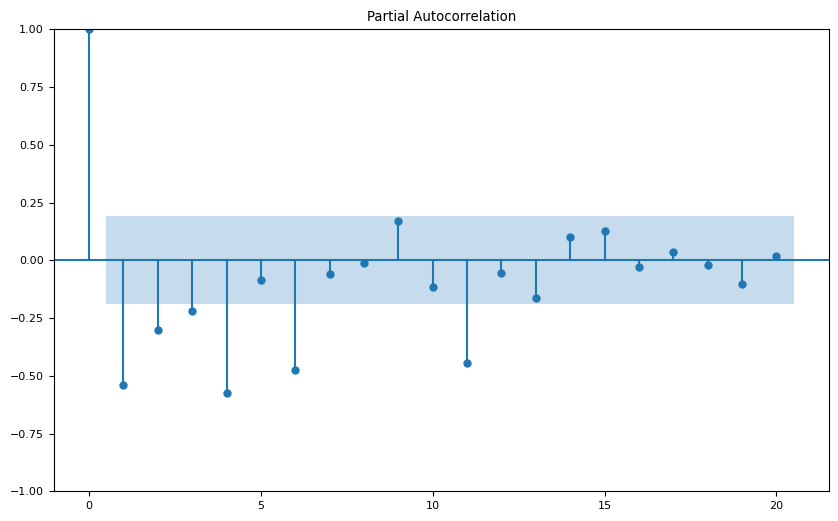

In [124]:
plot_pacf(x = series, lags = 20);  

based on above plot we can go either AR(1), AR(4), AR(6), or AR(10)

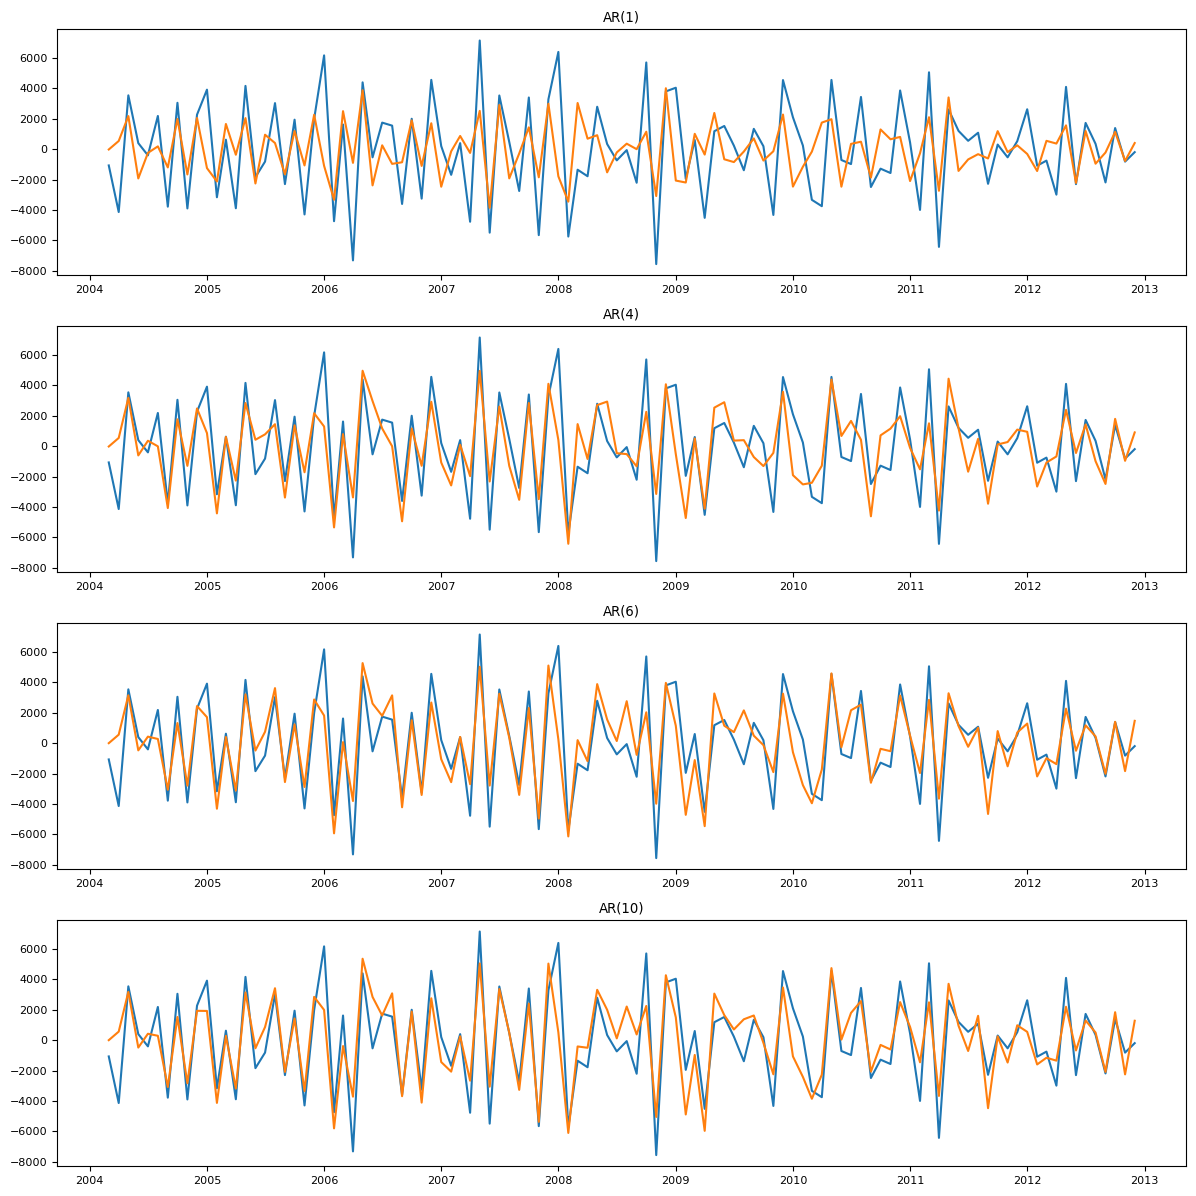

In [136]:
ar_orders = [1, 4, 6, 10]
plt.figure(figsize = (12,12))

# create AR(p) model
for idx,order in enumerate(ar_orders):
    model = ARIMA(series,order = (order,0,0))               # ARIMA()
    fitted_model = model.fit()                              # fit()
    plt.subplot(4, 1, idx + 1)
    plt.plot(series)
    plt.plot(fitted_model.fittedvalues)
    plt.title('AR({})'.format(order))
    
plt.tight_layout()                                          # tight_layout()

as we can see AR(6) is best fit, we dont see much advantage with AR(10) at the cost of 4 additional lags. And therefore we prefer AR(6) model

Each model has:
- a log likelihood (l)
- a number of parameters (k)
- a number of samples used for fitting (n)

**AIC** = 2k- 2l <br>
Lower AIC via higher log likelihood or less parameters

**BIC** = ln(n)k- 2l <br>
Lower BIC via higher log likelihood or less parameters or less samples used in fitting

In [139]:
for idx,order in enumerate(ar_orders):
    model = ARIMA(series,order = (order,0,0))              
    fitted_model = model.fit()                               
    print('AIC value for AR({}) is {}'.format(order,fitted_model.aic))

for idx,order in enumerate(ar_orders):
    model = ARIMA(series,order = (order,0,0))              
    fitted_model = model.fit()                               
    print('BIC value for AR({}) is {}'.format(order,fitted_model.bic))

AIC value for AR(1) is 1980.860621744531
AIC value for AR(4) is 1927.6099852660327
AIC value for AR(6) is 1899.649744257552
AIC value for AR(10) is 1902.3765450019482
BIC value for AR(1) is 1988.8509390268673
BIC value for AR(4) is 1943.590619830705
BIC value for AR(6) is 1920.9572570104485
BIC value for AR(10) is 1934.337814131293


# AR model

In [55]:
path = "C:\Admin\C Drive\Desktop\CQF Course\Python Labs\Self VAR\ice_cream.csv"
ice_cream = pd.read_csv(path, parse_dates=[0], index_col=0)
ice_cream = ice_cream.loc['2010-01-01':]

### To perform ADF test to confirm statinarity

In [112]:
adf_test = adfuller(ice_cream)
columns = ['test statistics','p-value','# of lagged values','# of observations']
adf_output_1 = pd.DataFrame([list(adf_test[0:4])],columns = columns)
dfstyler = adf_output_1.style.set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
dfstyler.set_properties(**{'text-align': 'center'}).hide(axis = 'index')

test statistics,p-value,# of lagged values,# of observations
-3.469207,0.008814,13,107


### ACF, PACF plot to select optimal lags

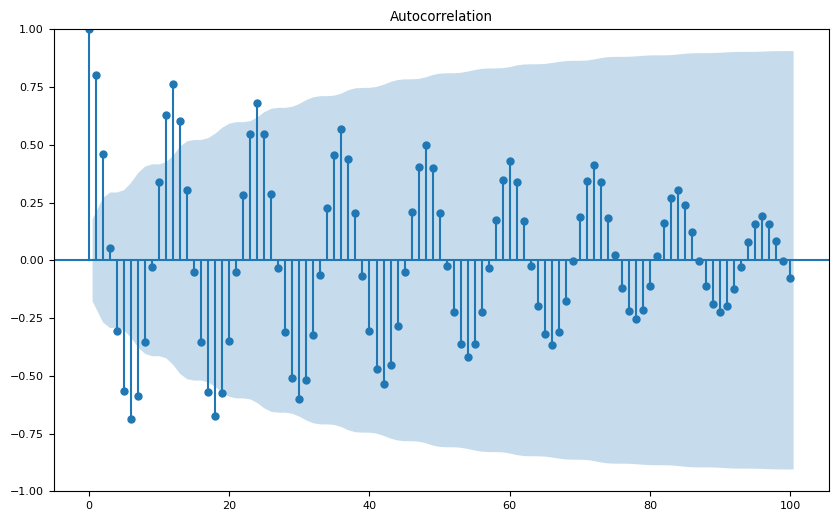

In [56]:
# firts peak is for 0th lag so not relevant
# anything under blue region is not statistically significant
# for AR model ACF is decaying which is the case here so this is definitely AR model
# plot_acf() and plot_pacf() are not final selection critria for lags selection, these are only starting points

plot_acf(x = ice_cream, lags = 100);             # plot_acf()

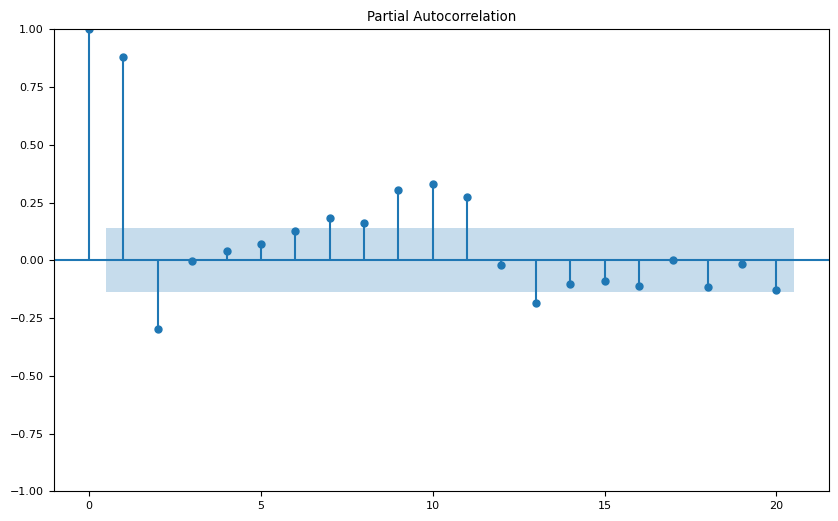

In [34]:
# firts peak is for 0th lag so not relevant
# based on analysis, you can consider 1,2,9,10,11 lags for AR model as a starting point

plot_pacf(ice_cream, lags = 20);             # plot_pacf()

In [71]:
# AR model

model = AutoReg(ice_cream,lags = 10)                       # AutoReg()
fitted_model = model.fit()                                 # fit()
fitted_model.resid                                         # resid
fitted_model.params                                        # params
fitted_model.summary()                                     # summary()
fitted_model.fittedvalues                                  # fittedvalues
fitted_model.aic                                           # aic
fitted_model.bic                                           # bic

<class 'statsmodels.iolib.summary.Summary'>
"""
                            AutoReg Model Results                             
==============================================================================
Dep. Variable:              IPN31152N   No. Observations:                  121
Model:                    AutoReg(10)   Log Likelihood                -346.880
Method:               Conditional MLE   S.D. of innovations              5.507
Date:                Tue, 02 Jan 2024   AIC                            717.760
Time:                        17:43:44   BIC                            750.275
Sample:                    11-01-2010   HQIC                           730.951
                         - 01-01-2020                                         
=================================================================================
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            40.8584     13.771      2.967      0.003      13.868      67.849
IPN31152N.L1      0.8362      0.081     10.298      0.000       0.677       0.995
IPN31152N.L2     -0.0770      0.107     -0.721      0.471      -0.286       0.132
IPN31152N.L3     -0.4208      0.107     -3.924      0.000      -0.631      -0.211
IPN31152N.L4      0.3221      0.105      3.064      0.002       0.116       0.528
IPN31152N.L5     -0.0122      0.097     -0.126      0.900      -0.202       0.178
IPN31152N.L6     -0.5004      0.097     -5.160      0.000      -0.690      -0.310
IPN31152N.L7      0.4188      0.104      4.028      0.000       0.215       0.623
IPN31152N.L8     -0.0653      0.106     -0.616      0.538      -0.273       0.143
IPN31152N.L9     -0.3972      0.107     -3.704      0.000      -0.607      -0.187
IPN31152N.L10     0.4957      0.077      6.432      0.000       0.345       0.647
                                    Roots                                     
==============================================================================
                   Real          Imaginary           Modulus         Frequency
------------------------------------------------------------------------------
AR.1            -1.1442           -0.0000j            1.1442           -0.5000
AR.2            -0.8889           -0.5763j            1.0594           -0.4085
AR.3            -0.8889           +0.5763j            1.0594            0.4085
AR.4            -0.0829           -1.0644j            1.0676           -0.2624
AR.5            -0.0829           +1.0644j            1.0676            0.2624
AR.6             0.5029           -0.9674j            1.0903           -0.1737
AR.7             0.5029           +0.9674j            1.0903            0.1737
AR.8             0.8768           -0.5075j            1.0130           -0.0835
AR.9             0.8768           +0.5075j            1.0130            0.0835
AR.10            1.1297           -0.0000j            1.1297           -0.0000
------------------------------------------------------------------------------
"""

In [68]:
# ARIMA model

model = ARIMA(ice_cream,order = (10,0,0))                  # ARIMA()
fitted_model = model.fit()                                 # fit()
fitted_model.resid                                         # resid
fitted_model.params                                        # params
fitted_model.summary()                                     # summary()
fitted_model.fittedvalues                                  # fittedvalues
fitted_model.aic                                           # aic
fitted_model.bic                                           # bic

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:              IPN31152N   No. Observations:                  121
Model:                ARIMA(10, 0, 0)   Log Likelihood                -387.621
Date:                Tue, 02 Jan 2024   AIC                            799.241
Time:                        16:36:52   BIC                            832.791
Sample:                    01-01-2010   HQIC                           812.867
                         - 01-01-2020                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        103.9205      2.157     48.185      0.000      99.693     108.148
ar.L1          0.9036      0.087     10.435      0.000       0.734       1.073
ar.L2         -0.0933      0.118     -0.792      0.428      -0.324       0.138
ar.L3         -0.3935      0.118     -3.337      0.001      -0.625      -0.162
ar.L4          0.3259      0.116      2.813      0.005       0.099       0.553
ar.L5         -0.0048      0.107     -0.045      0.964      -0.215       0.205
ar.L6         -0.4995      0.112     -4.478      0.000      -0.718      -0.281
ar.L7          0.4687      0.127      3.686      0.000       0.219       0.718
ar.L8         -0.0872      0.131     -0.667      0.505      -0.343       0.169
ar.L9         -0.3950      0.126     -3.143      0.002      -0.641      -0.149
ar.L10         0.5362      0.088      6.099      0.000       0.364       0.709
sigma2        33.3784      5.018      6.651      0.000      23.542      43.214
===================================================================================
Ljung-Box (L1) (Q):                   2.74   Jarque-Bera (JB):                 0.67
Prob(Q):                              0.10   Prob(JB):                         0.71
Heteroskedasticity (H):               1.26   Skew:                             0.15
Prob(H) (two-sided):                  0.47   Kurtosis:                         2.79
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

# VAR Model

#### Make sure time series used in VAR model are stationary

## Example 1

### Vector autoregressive models

For a general example of a VAR(p) with k variables, see General matrix notation of a VAR(p).

A VAR(1) in two variables can be written in matrix form (more compact notation) as

$$\begin{pmatrix} y_{1t} \\ y_{2t} \end{pmatrix} = \begin{bmatrix} a_{11} & a_{12} \\ a_{21} & a_{22}\end{bmatrix}\begin{pmatrix} y_{1t-1} \\ y_{2t-1} \end{pmatrix} + 
\begin{pmatrix} \epsilon_{1t} \\ \epsilon_{2t} 
\end{pmatrix}$$

or, more compactly,
$$ y_t = A_1 y_{t-1} + \epsilon_t,$$

where, $$y_t = \begin{pmatrix} y_{1t} \\ y_{2t} \end{pmatrix}, A_1= \begin{bmatrix} a_{11} & a_{12} \\ a_{21} & a_{22} \end{bmatrix} \text{and } \epsilon_t = \begin{pmatrix} \epsilon_{1t} \\ \epsilon_{2t} \end{pmatrix}.$$

Basically, such a model implies that everything depends on everything. But as can be seen from this formulation, each row can be written as a separate equation, so that 
$$ y_{1t} = a_{11} y_{1t-1} + a_{12} y_{2t-1} + \epsilon_{1t} $$
$$ y_{2t} = a_{21} y_{1t-1} + a_{22} y_{2t-1} + \epsilon_{2t} $$
Hence, the VAR model can be rewritten as a series of individual ADL models as described above. In fact, it is possible to estimate VAR models by estimating each equation separately.

In [69]:
filepath = r"C:\Admin\C Drive\Desktop\CQF Course\Python Labs\Self VAR\file_gdp.txt"
macro_data = pd.read_csv(filepath, parse_dates=['date'], index_col='date')

### To perform ADF test - these variables are I(1) processes

In [113]:
adf_test = adfuller(macro_data['rgnp'].diff(periods = 1)[1:])
columns = ['test statistics','p-value','# of lagged values','# of observations']
adf_output_1 = pd.DataFrame([list(adf_test[0:4])],columns = columns)
dfstyler = adf_output_1.style.set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
dfstyler.set_properties(**{'text-align': 'center'}).hide(axis = 'index')

adf_test = adfuller(macro_data['ulc'].diff(periods = 1)[1:])
columns = ['test statistics','p-value','# of lagged values','# of observations']
adf_output_1 = pd.DataFrame([list(adf_test[0:4])],columns = columns)
dfstyler = adf_output_1.style.set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
dfstyler.set_properties(**{'text-align': 'center'}).hide(axis = 'index')

test statistics,p-value,# of lagged values,# of observations
-3.576080,0.006235,1,120


### To perform Granger Causality test

In [6]:
# if p value is less than 0.05 then we can say that second variable causes first variable
# four tests are performed, however results are all four very similar
# we checked all four cases(lag 1, lag 2 , lag 3 and lag4) imply- rgnp causes ulc 

print('rgnp causes ulc?\n')
print('------------------')
granger_1 = grangercausalitytests(x = macro_data[['ulc','rgnp']] , maxlag = 4 )                 # grangercausalitytests() 

print('\nulc causes rgnp?\n')
print('------------------')
granger_2 = grangercausalitytests(macro_data[['rgnp', 'ulc']], 4)

rgnp causes ulc?

------------------

Granger Causality
number of lags (no zero) 1
ssr based F test:         F=22.3802 , p=0.0000  , df_denom=119, df_num=1
ssr based chi2 test:   chi2=22.9444 , p=0.0000  , df=1
likelihood ratio test: chi2=21.0242 , p=0.0000  , df=1
parameter F test:         F=22.3802 , p=0.0000  , df_denom=119, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=7.7188  , p=0.0007  , df_denom=116, df_num=2
ssr based chi2 test:   chi2=16.1029 , p=0.0003  , df=2
likelihood ratio test: chi2=15.1179 , p=0.0005  , df=2
parameter F test:         F=7.7188  , p=0.0007  , df_denom=116, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=7.5231  , p=0.0001  , df_denom=113, df_num=3
ssr based chi2 test:   chi2=23.9675 , p=0.0000  , df=3
likelihood ratio test: chi2=21.8515 , p=0.0001  , df=3
parameter F test:         F=7.5231  , p=0.0001  , df_denom=113, df_num=3

Granger Causality
number of lags (no zero) 4
ssr based F

### To fit VAR model - on stationary variables

In [7]:
df = macro_data[['ulc','rgnp']]
train_df = df.iloc[:-12]
test_df = df.iloc[-12:]

In [15]:
model = VAR(endog = train_df.diff(periods = 1)[1:])    # VAR() -Fit VAR(p) process and do lag order selection
sorted_order = model.select_order(maxlags =20)         # select_order()

# shows that lag 4 AIC-BIC values are lowest and hence 4 is optimal lag 

print(sorted_order.summary())                          # summary()

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0        6.778       6.834       878.3       6.800
1        5.988      6.154*       398.5       6.055
2        5.942       6.220       380.9       6.054
3        5.933       6.322       377.4       6.090
4       5.793*       6.293      328.5*      5.995*
5        5.873       6.484       356.3       6.120
6        5.828       6.550       341.1       6.119
7        5.894       6.727       365.0       6.230
8        5.890       6.835       364.8       6.271
9        5.942       6.998       385.8       6.368
10       5.930       7.097       382.9       6.401
11       5.913       7.191       378.5       6.428
12       5.885       7.274       370.7       6.445
13       5.925       7.424       388.6       6.529
14       5.882       7.493       376.0       6.532
15       5.950       7.672       406.9       6.644
16       5.933       7.766     

In [16]:
model = VAR(endog = train_df.diff(periods = 1)[1:])    # VAR() -Fit VAR(p) process and do lag order selection
fitted_model = model.fit(maxlags=10,ic = 'aic')        # fit()
fitted_model.summary()                                 # summary()          

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Fri, 29, Dec, 2023
Time:                     16:19:48
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                    5.98996
Nobs:                     106.000    HQIC:                   5.72099
Log likelihood:          -576.312    FPE:                    254.297
AIC:                      5.53768    Det(Omega_mle):         216.051
--------------------------------------------------------------------
Results for equation ulc
             coefficient       std. error           t-stat            prob
--------------------------------------------------------------------------
const          -0.582681         0.179496           -3.246           0.001
L1.ulc          0.432987         0.124725            3.472           0.001
L1.rgnp         0.009494         0.003476            2.731           0.006
L2.ulc     

In [19]:
# here we are passing non-stationary varibles with enforce stationarity condition - not a good idea for only VAR model
# order means (p,q) - lag p AR and lag q MA
# this is ARMA model fitting (VARMAX)

var_model = VARMAX(endog = train_df,order =(4,0),enforce_stationarity=True)           # VARMAX()
fitted_model = var_model.fit(disp = False)                                            # fit()
fitted_model.resid                                                                    # resid
fitted_model.params                                                                   # params
fitted_model.summary()                                                                # summary()                                                           
fitted_model.fittedvalues                                                             # fittedvalues
fitted_model.aic                                                                      # aic
fitted_model.bic                                                                      # bic

AttributeError: 'VARMAXResults' object has no attribute 'p_value'

 ## Example 2

### A matrix formulation of the multiple regression model

In the multiple regression setting, because of the potentially large number of predictors, it is more efficient to use matrices to define the regression model and the subsequent analyses. Here, we review basic matrix algebra, as well as learn some of the more important multiple regression formulas in matrix form.

As always, let's start with the simple case first. Consider the following simple linear regression function:

$y_i=\beta_0+\beta_1x_i+\epsilon_i  \;\;\;\;\;\;\; \text {for } i=1, ... , n$

$$\begin{align} y_1 & =\beta_0+\beta_1x_1+\epsilon_1 \\ y_2 & =\beta_0+\beta_1x_2+\epsilon_2 \\ \vdots \\ y_n & = \beta_0+\beta_1x_n+\epsilon_n \end{align}$$

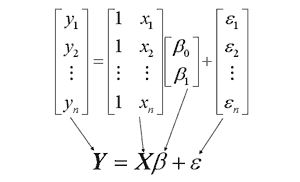

In [58]:
path = r"C:\Users\Admin\CQF\VAR_multiple_regression_1.JPG"
Image.open(path)

In [46]:
path = r"C:\Users\Admin\CQF\sales.csv"
df = pd.read_csv(path)

In [55]:
X = df.drop(columns = 'Sales')
X.insert(0,'Bias',value = 1)
y= df['Sales']

In [56]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.25,random_state=42)

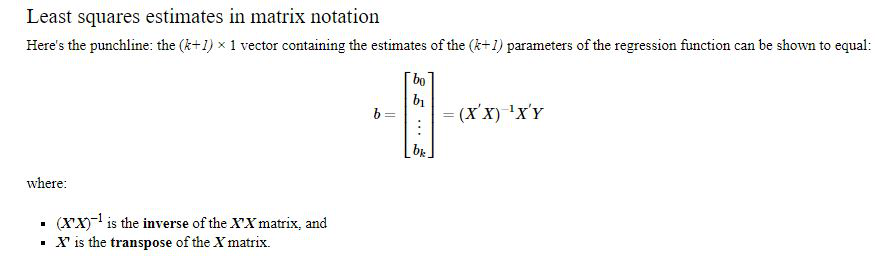

In [59]:
path = r"C:\Users\Admin\CQF\VAR_multiple_regression_2.JPG"
Image.open(path)

In [60]:
beta = np.linalg.multi_dot([np.linalg.inv(np.dot(x_train.T,x_train)),x_train.T,y_train])
beta[0], beta[1:]

### Predict y and calculate error

In [67]:
# RSS = residual sum of squares
# SSE = sum of squares of error = RSS
# SSR = sum of squares of regression, some people call it sum of square of residuals , very confusing !! be careful
# SST = SSR + RSS/SSE

model_ouput = np.multiply(x_test, beta)
y_hat = np.sum(model_ouput)

rss = np.sum((y_test - y_hat)**2)              # rss = residual sum of squares (RSS) 
mse = rss/len(y_test)                          # mse - mean squared error